In [1]:
import numpy as np
import matplotlib.pyplot as plt

from superfv.tools.stability_analysis.sd_advection import plot_sd_advection_stability_trace
from superfv.tools.stability_analysis.rk import ssprk3_amplification, plot_stability_region, compute_rk_amplification

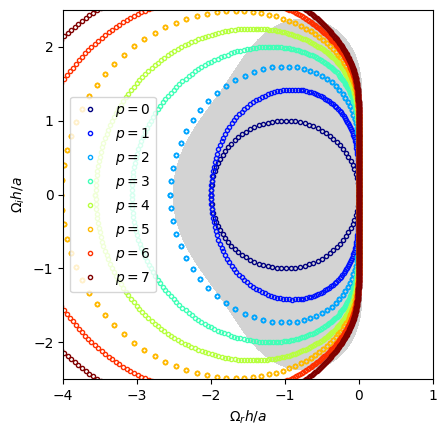

In [2]:
xlim = -4, 1
ylim = -2.5, 2.5
nmesh = 256

fig, ax = plt.subplots()
ax.set_xlabel(r"$\Omega_r h / a$")
ax.set_ylabel(r"$\Omega_i h / a$")
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal')

# ASSUMES CFL=1.0
plot_stability_region(ax, ssprk3_amplification, np.linspace(xlim[0], xlim[1], nmesh), np.linspace(ylim[0], ylim[1], nmesh), levels=[0.0, 1.0], colors="lightgrey", fill=True)

k_values = np.linspace(-np.pi, np.pi, 100)
for p in range(8):
    plot_sd_advection_stability_trace(ax, p, k_values, color=plt.cm.jet(p / 7), label=fr"$p={p}$")

ax.legend()

In [3]:
for cfl_value in np.arange(0.4, 1.05, 0.05):
    max_amplification_p3 = compute_rk_amplification(3, k_values, cfl_value, scheme="sd")
    max_amplification_p7 = compute_rk_amplification(7, k_values, cfl_value, scheme="sd")
    print(f"CFL={cfl_value:.2f}: max amplification-1 p=3: {max_amplification_p3-1:.2e}, p=7: {max_amplification_p7-1:.2e}")


CFL=0.40: max amplification-1 p=3: 0.00e+00, p=7: 9.99e-15
CFL=0.45: max amplification-1 p=3: 0.00e+00, p=7: 1.11e-14
CFL=0.50: max amplification-1 p=3: 0.00e+00, p=7: 1.24e-14
CFL=0.55: max amplification-1 p=3: 0.00e+00, p=7: 3.12e-01
CFL=0.60: max amplification-1 p=3: 0.00e+00, p=7: 8.35e-01
CFL=0.65: max amplification-1 p=3: 0.00e+00, p=7: 1.47e+00
CFL=0.70: max amplification-1 p=3: 0.00e+00, p=7: 2.24e+00
CFL=0.75: max amplification-1 p=3: 0.00e+00, p=7: 3.15e+00
CFL=0.80: max amplification-1 p=3: 0.00e+00, p=7: 4.23e+00
CFL=0.85: max amplification-1 p=3: 1.91e-01, p=7: 5.47e+00
CFL=0.90: max amplification-1 p=3: 4.69e-01, p=7: 6.91e+00
CFL=0.95: max amplification-1 p=3: 8.07e-01, p=7: 8.54e+00
CFL=1.00: max amplification-1 p=3: 1.19e+00, p=7: 1.04e+01
